<a href="https://colab.research.google.com/github/derykian/2418005-Data-Visualization/blob/main/2418005DataVisualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Import library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

#2. Upload dataset di Google Colab

In [3]:
from google.colab import files
uploaded = files.upload()

# Mendapatkan nama berkas yang diunggah
file_name = list(uploaded.keys())[0]

# Membaca berkas sesuai format (CSV atau Excel)
if file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name, parse_dates=["Hire Date"])
elif file_name.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_name, parse_dates=["Hire Date"])
else:
    raise ValueError("Format berkas tidak didukung. Harap unggah berkas CSV atau Excel.")

print("Ukuran dataset:", df.shape)
display(df.head())

Saving Employee_Management_Data_Cleansed_Enriched.xlsx to Employee_Management_Data_Cleansed_Enriched (1).xlsx
Ukuran dataset: (40, 11)


,Unnamed: 0,Employee ID,Full Name,Department,Designation,Hire Date,Annual Salary (USD),Hire Year,Years of Service,Service Category,Monthly Salary (USD)
0,NaN,S1001,John Smith,Human Resources,HR Manager,2023-05-15,60000,2023,3.39,Menengah,5000.00
1,NaN,S1002,Jane Doe,Marketing,Marketing Specialist,2023-08-20,50000,2023,3.12,Menengah,4166.67
2,NaN,S1003,Michael Johnson,Finance,Financial Analyst,2023-10-10,55000,2023,2.98,Menengah,4583.33
3,NaN,S1004,Emily Brown,Sales,Sales Representative,2023-03-25,48000,2023,3.53,Menengah,4000.00
4,NaN,S1005,David Wilson,Information Technology,IT Specialist,2023-09-12,60000,2023,3.06,Menengah,5000.00


#3. Memeriksa kualitas data

In [4]:
print("Informasi dataset:")
df.info()

print("\nJumlah nilai kosong per kolom:")
display(df.isna().sum().to_frame("Missing Values"))

print("Jumlah baris duplikat:", df.duplicated().sum())
print("Jumlah departemen:", df["Department"].nunique())
print("Tanggal perekrutan:", df["Hire Date"].min().date(), "sampai", df["Hire Date"].max().date())

display(df.describe(include="all").transpose())

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Unnamed: 0            0 non-null      float64       
 1   Employee ID           40 non-null     object        
 2   Full Name             40 non-null     object        
 3   Department            40 non-null     object        
 4   Designation           40 non-null     object        
 5   Hire Date             40 non-null     datetime64[ns]
 6   Annual Salary (USD)   40 non-null     int64         
 7   Hire Year             40 non-null     int64         
 8   Years of Service      40 non-null     float64       
 9   Service Category      40 non-null     object        
 10  Monthly Salary (USD)  40 non-null     float64       
dtypes: datetime64[ns](1), float64(3), int64(2), object(5)
memory usage: 3.6+ KB

Jumlah nilai kosong per kolom:


,Missing Values
Unnamed: 0,40
Employee ID,0
Full Name,0
Department,0
Designation,0
Hire Date,0
Annual Salary (USD),0
Hire Year,0
Years of Service,0
Service Category,0


Jumlah baris duplikat: 0
Jumlah departemen: 10
Tanggal perekrutan: 2023-01-17 sampai 2023-12-03


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Unnamed: 0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employee ID,40,40,S1001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Full Name,40,37,Michael Johnson,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,40,10,Human Resources,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Designation,40,40,HR Manager,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hire Date,40,NaN,NaN,NaN,2023-07-10 13:12:00,2023-01-17 00:00:00,2023-04-25 12:00:00,2023-07-11 00:00:00,2023-09-22 12:00:00,2023-12-03 00:00:00,NaN
Annual Salary (USD),40.0,NaN,NaN,NaN,55150.0,40000.0,48000.0,53500.0,62750.0,75000.0,10654.359888
Hire Year,40.0,NaN,NaN,NaN,2023.0,2023.0,2023.0,2023.0,2023.0,2023.0,0.0
Years of Service,40.0,NaN,NaN,NaN,3.2315,2.83,3.0325,3.23,3.4375,3.71,0.248075
Service Category,40,1,Menengah,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#4. Histogram distribusi gaji tahunan

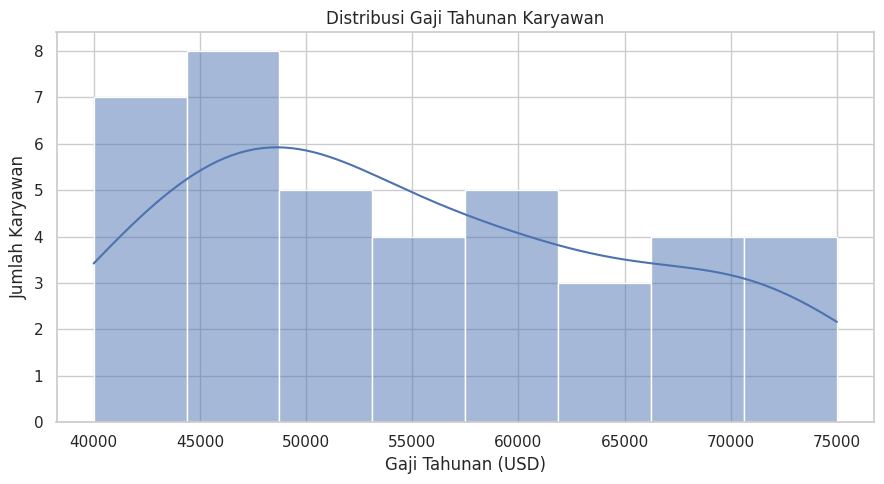

Rata-rata gaji tahunan: $55,150.00
Median gaji tahunan: $53,500.00
Rentang gaji: $40,000–$75,000


In [5]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Annual Salary (USD)", bins=8, kde=True)
plt.title("Distribusi Gaji Tahunan Karyawan")
plt.xlabel("Gaji Tahunan (USD)")
plt.ylabel("Jumlah Karyawan")
plt.tight_layout()
plt.show()

print(f"Rata-rata gaji tahunan: ${df['Annual Salary (USD)'].mean():,.2f}")
print(f"Median gaji tahunan: ${df['Annual Salary (USD)'].median():,.2f}")
print(f"Rentang gaji: ${df['Annual Salary (USD)'].min():,.0f}–${df['Annual Salary (USD)'].max():,.0f}")

#5. Bar chart jumlah karyawan per departemen

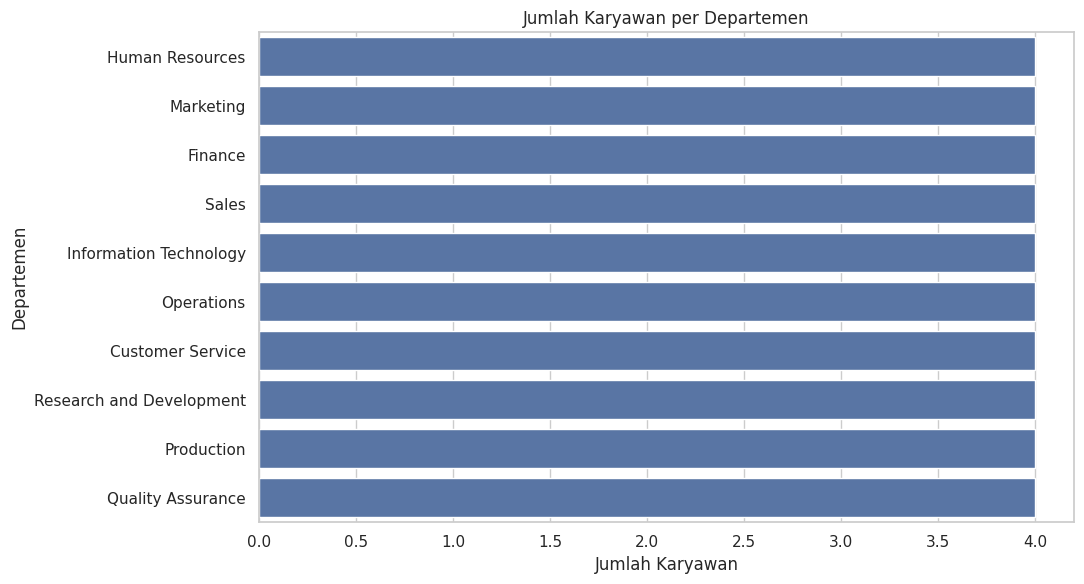

,Jumlah Karyawan
Department,
Human Resources,4
Marketing,4
Finance,4
Sales,4
Information Technology,4
Operations,4
Customer Service,4
Research and Development,4
Production,4


In [6]:
department_counts = df["Department"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(11, 6))
sns.barplot(x=department_counts.values, y=department_counts.index)
plt.title("Jumlah Karyawan per Departemen")
plt.xlabel("Jumlah Karyawan")
plt.ylabel("Departemen")
plt.tight_layout()
plt.show()

display(department_counts.rename("Jumlah Karyawan").to_frame())

#6. Boxplot gaji tahunan berdasarkan departemen

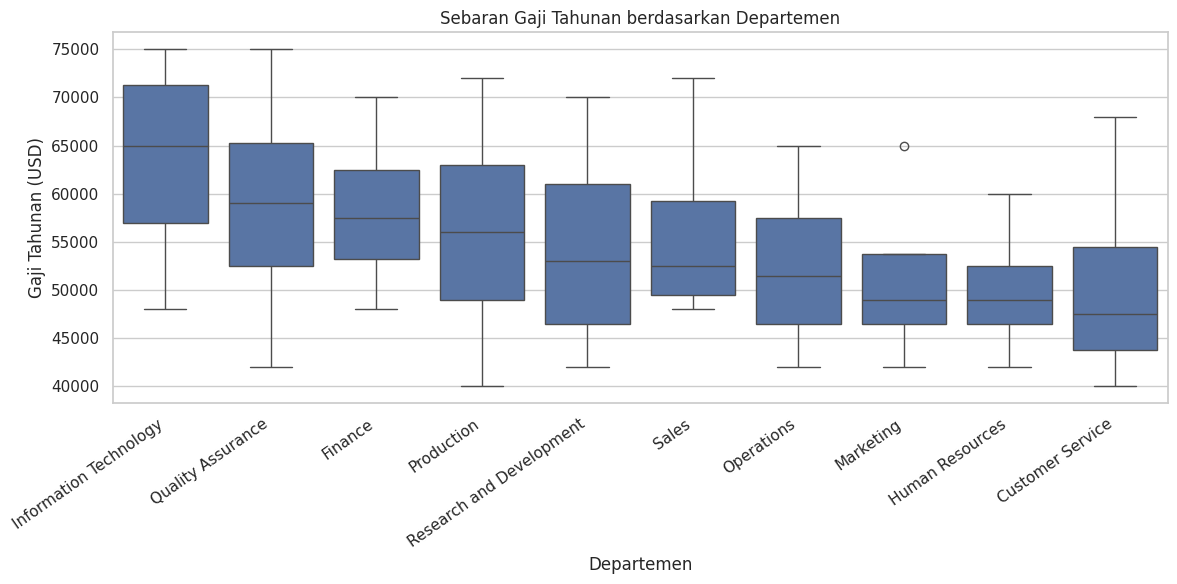

,count,mean,median,min,max
Department,,,,,
Information Technology,4,63250.0,65000.0,48000,75000
Quality Assurance,4,58750.0,59000.0,42000,75000
Finance,4,58250.0,57500.0,48000,70000
Production,4,56000.0,56000.0,40000,72000
Research and Development,4,54500.0,53000.0,42000,70000
Sales,4,56250.0,52500.0,48000,72000
Operations,4,52500.0,51500.0,42000,65000
Marketing,4,51250.0,49000.0,42000,65000
Human Resources,4,50000.0,49000.0,42000,60000


In [7]:
department_order = (
    df.groupby("Department")["Annual Salary (USD)"]
      .median()
      .sort_values(ascending=False)
      .index
)

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Department", y="Annual Salary (USD)", order=department_order)
plt.title("Sebaran Gaji Tahunan berdasarkan Departemen")
plt.xlabel("Departemen")
plt.ylabel("Gaji Tahunan (USD)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

salary_summary = (
    df.groupby("Department")["Annual Salary (USD)"]
      .agg(["count", "mean", "median", "min", "max"])
      .sort_values("median", ascending=False)
)
display(salary_summary.round(2))

#7. Scatter plot masa kerja dan gaji tahunan

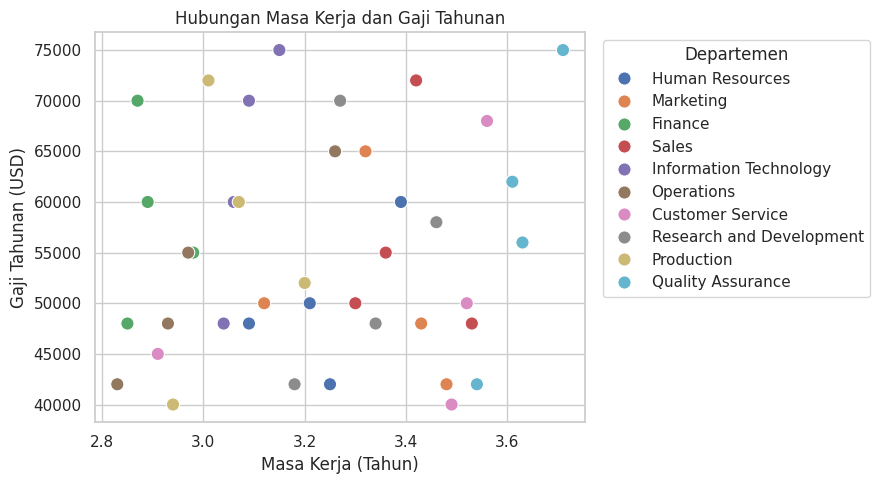

Korelasi Pearson masa kerja dan gaji tahunan: 0.106


In [8]:
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="Years of Service",
    y="Annual Salary (USD)",
    hue="Department",
    s=90
)
plt.title("Hubungan Masa Kerja dan Gaji Tahunan")
plt.xlabel("Masa Kerja (Tahun)")
plt.ylabel("Gaji Tahunan (USD)")
plt.legend(title="Departemen", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

correlation = df["Years of Service"].corr(df["Annual Salary (USD)"])
print(f"Korelasi Pearson masa kerja dan gaji tahunan: {correlation:.3f}")

#8. Line chart jumlah perekrutan per bulan

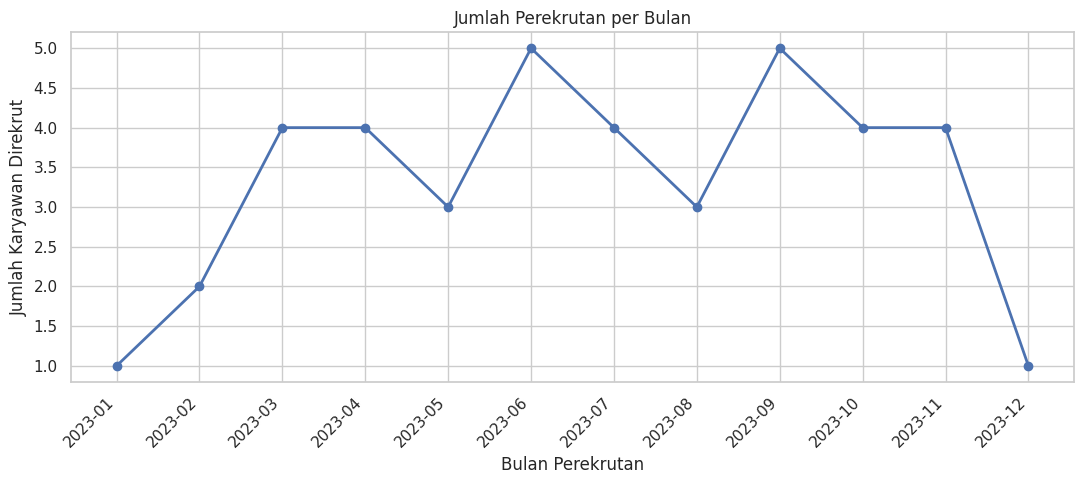

,Jumlah Perekrutan
Hire Month,
2023-01,1
2023-02,2
2023-03,4
2023-04,4
2023-05,3
2023-06,5
2023-07,4
2023-08,3
2023-09,5


In [9]:
df["Hire Month"] = df["Hire Date"].dt.to_period("M").astype(str)
monthly_hires = df.groupby("Hire Month").size()

plt.figure(figsize=(11, 5))
plt.plot(monthly_hires.index, monthly_hires.values, marker="o", linewidth=2)
plt.title("Jumlah Perekrutan per Bulan")
plt.xlabel("Bulan Perekrutan")
plt.ylabel("Jumlah Karyawan Direkrut")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(monthly_hires.rename("Jumlah Perekrutan").to_frame())

#9. Heatmap korelasi variabel numerik

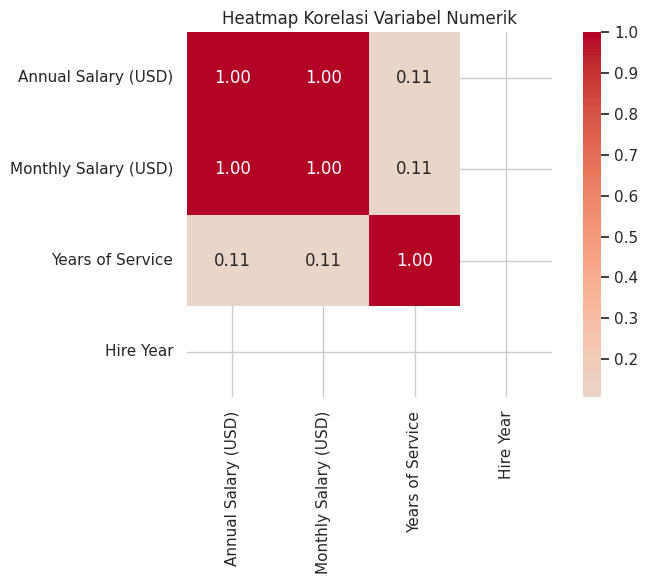

In [10]:
numeric_columns = [
    "Annual Salary (USD)",
    "Monthly Salary (USD)",
    "Years of Service",
    "Hire Year"
]
correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)
plt.title("Heatmap Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

#10. Kesimpulan

1. Dataset memiliki 40 baris dan mendukung beberapa jenis visualisasi eksploratif.
2. Histogram memperlihatkan distribusi gaji tahunan.
3. Bar chart menunjukkan komposisi jumlah data karyawan per departemen.
4. Boxplot membantu membandingkan sebaran gaji antar-departemen.
5. Scatter plot dan heatmap membantu mengeksplorasi hubungan antarvariabel, tetapi korelasi tidak membuktikan sebab-akibat.
6. Line chart merangkum jumlah perekrutan per bulan pada tahun 2023.
7. Dataset terbatas pada 40 baris, seluruh tanggal perekrutan pada 2023, dan satu kategori masa kerja. Hasilnya bersifat deskriptif dan tidak boleh digeneralisasi ke semua organisasi.

#11. Simpan ringkasan hasil

In [11]:
department_summary = (
    df.groupby("Department")
      .agg(
          Employee_Count=("Department", "size"),
          Mean_Annual_Salary=("Annual Salary (USD)", "mean"),
          Median_Annual_Salary=("Annual Salary (USD)", "median")
      )
      .sort_values("Median_Annual_Salary", ascending=False)
)

display(department_summary.round(2))
department_summary.to_csv("department_salary_summary.csv")
print("Ringkasan tersimpan sebagai department_salary_summary.csv")

,Employee_Count,Mean_Annual_Salary,Median_Annual_Salary
Department,,,
Information Technology,4,63250.0,65000.0
Quality Assurance,4,58750.0,59000.0
Finance,4,58250.0,57500.0
Production,4,56000.0,56000.0
Research and Development,4,54500.0,53000.0
Sales,4,56250.0,52500.0
Operations,4,52500.0,51500.0
Marketing,4,51250.0,49000.0
Human Resources,4,50000.0,49000.0


Ringkasan tersimpan sebagai department_salary_summary.csv
